In [1]:
import pandas as pd
from functools import reduce

# Load all files
tchol  = pd.read_sas('/Users/heidisaldana/Downloads/TCHOL_L.xpt', format='xport')
bmx    = pd.read_sas('/Users/heidisaldana/Downloads/BMX_L.xpt', format='xport')
smq    = pd.read_sas('/Users/heidisaldana/Downloads/SMQ_L.xpt', format='xport')
rxq    = pd.read_sas('/Users/heidisaldana/Downloads/RXQ_RX_L.xpt', format='xport')
bpxo   = pd.read_sas('/Users/heidisaldana/Downloads/BPXO_L.xpt', format='xport')
bpq    = pd.read_sas('/Users/heidisaldana/Downloads/BPQ_L.xpt', format='xport')
demo   = pd.read_sas('/Users/heidisaldana/Downloads/DEMO_L.xpt', format='xport')
mcq    = pd.read_sas('/Users/heidisaldana/Downloads/MCQ_L.xpt', format='xport')

# RXQ has multiple rows per person — collapse to one row first.
# Only contains yes/no medication fields — too coarse to be clinically
# meaningful, so excluded from modeling features.
rxq_wide = rxq.groupby('SEQN').first().reset_index()

# Merge all on SEQN
dfs = [demo, tchol, bmx, smq, rxq_wide, bpxo, bpq, mcq]
merged = reduce(lambda a, b: pd.merge(a, b, on='SEQN', how='left'), dfs)

print(merged.shape)
print(merged.head())

(11933, 111)
       SEQN  SDDSRVYR  RIDSTATR  RIAGENDR  RIDAGEYR  RIDAGEMN  RIDRETH1  \
0  130378.0      12.0       2.0       1.0      43.0       NaN       5.0   
1  130379.0      12.0       2.0       1.0      66.0       NaN       3.0   
2  130380.0      12.0       2.0       2.0      44.0       NaN       2.0   
3  130381.0      12.0       2.0       2.0       5.0       NaN       5.0   
4  130382.0      12.0       2.0       1.0       2.0       NaN       3.0   

   RIDRETH3  RIDEXMON  RIDEXAGM  ...  MCQ510E  MCQ510F  MCQ550  MCQ560  \
0       6.0       2.0       NaN  ...      NaN      NaN     2.0     2.0   
1       3.0       2.0       NaN  ...      NaN      NaN     2.0     2.0   
2       2.0       1.0       NaN  ...      NaN      NaN     2.0     2.0   
3       7.0       1.0      71.0  ...      NaN      NaN     NaN     NaN   
4       3.0       2.0      34.0  ...      NaN      NaN     NaN     NaN   

   MCQ220  MCQ230A  MCQ230B  MCQ230C  MCQ230D  OSQ230  
0     2.0      NaN      NaN      Na

/var/folders/yr/mz3y3py154ld221bs53ym6yh0000gn/T/ipykernel_72954/1011023354.py:6: UserWarning: xport file may be corrupted.
  bmx    = pd.read_sas('/Users/heidisaldana/Downloads/BMX_L.xpt', format='xport')


## ⚠️ A Note on Survey Weights

NHANES uses a complex sampling design that intentionally **oversamples** 
certain minority groups (e.g. NH Black, Hispanic populations) to ensure 
enough data is collected on smaller subgroups for reliable estimates.

To make results representative of the **true U.S. population**, survey 
weights (provided in the DEMO file as `WTMEC2YR`) should be applied. 
In this analysis, survey weights were **not applied** — meaning the charts 
below reflect raw sample counts, not national population proportions. 
This is why NH White appears dominant; it is partly a reflection of 
the unweighted sample composition, not necessarily true population prevalence.

**Limitation:** All prevalence estimates (e.g. hypertension rates by race) 
should be interpreted as sample-level observations, not nationally 
representative statistics. A future extension of this project would apply 
survey weights using a package like `statsmodels` with survey design support.

In [3]:
# =============================================================================
# NHANES Cardiovascular Risk — Data Cleaning & Preparation
# =============================================================================
# Dataset: NHANES Cycle L (2021–2023)
# Goal: Build a clean, analysis-ready dataset to explore cardiovascular risk
#       factors across demographic groups in the U.S. population.
#
# Files used:
#   DEMO_L  — Demographics (age, sex, race, education, income)
#   TCHOL_L — Total cholesterol
#   BMX_L   — Body measurements (BMI, waist circumference)
#   BPXO_L  — Oscillometric blood pressure readings
#   BPQ_L   — Blood pressure questionnaire (diagnosis, medication)
#   SMQ_L   — Smoking history
#   MCQ_L   — Medical conditions (heart disease, stroke, diabetes, etc.)
# =============================================================================

import pandas as pd
import numpy as np
from functools import reduce

# -----------------------------------------------------------------------------
# STEP 1: Load raw files
# -----------------------------------------------------------------------------

print("Loading raw NHANES files...")

demo  = pd.read_sas('/Users/heidisaldana/Downloads/DEMO_L.xpt', format='xport')
tchol = pd.read_sas('/Users/heidisaldana/Downloads/TCHOL_L.xpt', format='xport')
bmx   = pd.read_sas('/Users/heidisaldana/Downloads/BMX_L.xpt', format='xport')
bpxo  = pd.read_sas('/Users/heidisaldana/Downloads/BPXO_L.xpt', format='xport')
bpq   = pd.read_sas('/Users/heidisaldana/Downloads/BPQ_L.xpt', format='xport')
smq   = pd.read_sas('/Users/heidisaldana/Downloads/SMQ_L.xpt', format='xport')
mcq   = pd.read_sas('/Users/heidisaldana/Downloads/MCQ_L.xpt', format='xport')

print(f"  DEMO:  {demo.shape}")
print(f"  TCHOL: {tchol.shape}")
print(f"  BMX:   {bmx.shape}")
print(f"  BPXO:  {bpxo.shape}")
print(f"  BPQ:   {bpq.shape}")
print(f"  SMQ:   {smq.shape}")
print(f"  MCQ:   {mcq.shape}")

# -----------------------------------------------------------------------------
# STEP 2: Select relevant columns from each file
# -----------------------------------------------------------------------------
# We keep only variables with clinical or demographic meaning for
# cardiovascular risk. Variables with >85% missingness (e.g. SMD650 —
# cigarettes per day) are dropped as they are not usable for analysis.

demo_cols  = demo[['SEQN', 'RIAGENDR', 'RIDAGEYR', 'RIDRETH3',
                    'DMDEDUC2', 'INDFMPIR']]

tchol_cols = tchol[['SEQN', 'LBXTC']]

bmx_cols   = bmx[['SEQN', 'BMXBMI', 'BMXWAIST']]

bpxo_cols  = bpxo[['SEQN',
                    'BPXOSY1', 'BPXOSY2', 'BPXOSY3',   # systolic readings
                    'BPXODI1', 'BPXODI2', 'BPXODI3']]  # diastolic readings

bpq_cols   = bpq[['SEQN', 'BPQ020', 'BPQ080']]

smq_cols   = smq[['SEQN', 'SMQ020']]

mcq_cols   = mcq[['SEQN',
                   'MCQ160A',  # arthritis
                   'MCQ160B',  # congestive heart failure
                   'MCQ160C',  # coronary heart disease
                   'MCQ160E',  # heart attack
                   'MCQ160F',  # stroke
                   'MCQ220']]  # diabetes

# -----------------------------------------------------------------------------
# STEP 3: Average the 3 blood pressure readings per participant
# -----------------------------------------------------------------------------
# NHANES takes 3 oscillometric BP readings per visit. The standard approach
# is to average all available readings per participant. This reduces
# measurement noise and is consistent with clinical BP assessment guidelines.

print("\nAveraging blood pressure readings...")

bpxo_cols = bpxo_cols.copy()
bpxo_cols['systolic_bp']  = bpxo_cols[['BPXOSY1','BPXOSY2','BPXOSY3']].mean(axis=1)
bpxo_cols['diastolic_bp'] = bpxo_cols[['BPXODI1','BPXODI2','BPXODI3']].mean(axis=1)
bpxo_final = bpxo_cols[['SEQN', 'systolic_bp', 'diastolic_bp']]

# -----------------------------------------------------------------------------
# STEP 4: Merge all files on SEQN
# -----------------------------------------------------------------------------
# SEQN is NHANES' unique respondent ID — the common key across all files.
# We use a left merge starting from DEMO (the largest file, 11,933 participants)
# so that all respondents are retained even if they're missing from
# lab or exam files (e.g. children who weren't given cholesterol tests).

print("Merging all files on SEQN...")

dfs = [demo_cols, tchol_cols, bmx_cols, bpxo_final, bpq_cols, smq_cols, mcq_cols]
merged = reduce(lambda a, b: pd.merge(a, b, on='SEQN', how='left'), dfs)

print(f"  Merged shape: {merged.shape}")

# -----------------------------------------------------------------------------
# STEP 5: Rename columns to human-readable names
# -----------------------------------------------------------------------------

merged = merged.rename(columns={
    'SEQN':     'respondent_id',
    'RIAGENDR': 'gender',           # 1 = Male, 2 = Female
    'RIDAGEYR': 'age',
    'RIDRETH3': 'race_ethnicity',   # 1=Mexican American, 2=Other Hispanic,
                                    # 3=Non-Hispanic White, 4=Non-Hispanic Black,
                                    # 6=Non-Hispanic Asian, 7=Other/Multiracial
    'DMDEDUC2': 'education',        # 1=<9th grade ... 5=College grad+
    'INDFMPIR': 'income_poverty_ratio',
    'LBXTC':    'total_cholesterol_mgdl',
    'BMXBMI':   'bmi',
    'BMXWAIST': 'waist_cm',
    'BPQ020':   'told_high_bp',     # 1 = Yes, 2 = No
    'BPQ080':   'bp_medication',    # 1 = Yes, 2 = No
    'SMQ020':   'ever_smoked',      # 1 = Yes, 2 = No
    'MCQ160A':  'has_arthritis',
    'MCQ160B':  'has_heart_failure',
    'MCQ160C':  'has_chd',          # coronary heart disease
    'MCQ160E':  'had_heart_attack',
    'MCQ160F':  'had_stroke',
    'MCQ220':   'has_diabetes',
})

# -----------------------------------------------------------------------------
# STEP 6: Recode binary variables from 1/2 to 1/0
# -----------------------------------------------------------------------------
# NHANES codes Yes/No as 1/2. We recode to standard 1/0 for modeling.
# Values of 7 (Refused) and 9 (Don't know) are treated as missing.

print("Recoding binary variables...")

binary_cols = [
    'told_high_bp', 'bp_medication', 'ever_smoked',
    'has_arthritis', 'has_heart_failure', 'has_chd',
    'had_heart_attack', 'had_stroke', 'has_diabetes'
]

for col in binary_cols:
    merged[col] = merged[col].replace({1: 1, 2: 0, 7: np.nan, 9: np.nan})

# Recode gender: 1=Male → 0, 2=Female → 1
merged['gender'] = merged['gender'].replace({1: 0, 2: 1})
# gender: 0 = Male, 1 = Female

# -----------------------------------------------------------------------------
# STEP 7: Create the outcome variable — hypertension
# -----------------------------------------------------------------------------
# A participant is classified as hypertensive if ANY of the following are true:
#   - Systolic BP >= 130 mmHg  (Stage 1 hypertension per ACC/AHA 2017)
#   - Diastolic BP >= 80 mmHg
#   - Previously told they have high BP (BPQ020 = Yes)
#   - Currently taking BP medication (BPQ080 = Yes)
#
# This composite definition is standard in epidemiological research and
# captures both measured and self-reported hypertension.

print("Creating hypertension outcome variable...")

merged['hypertension'] = (
    (merged['systolic_bp']  >= 130) |
    (merged['diastolic_bp'] >= 80)  |
    (merged['told_high_bp'] == 1)   |
    (merged['bp_medication'] == 1)
).astype(float)

# Set to NaN if all BP inputs were missing
bp_all_missing = (
    merged['systolic_bp'].isna() &
    merged['diastolic_bp'].isna() &
    merged['told_high_bp'].isna() &
    merged['bp_medication'].isna()
)
merged.loc[bp_all_missing, 'hypertension'] = np.nan

# -----------------------------------------------------------------------------
# STEP 8: Handle missing data
# -----------------------------------------------------------------------------
# Strategy:
#   - Continuous variables (BMI, waist, cholesterol, BP, income):
#     impute with median — robust to outliers and skewed distributions
#   - Binary/categorical variables (smoking, disease history, education):
#     impute with mode — preserves the most common response
#   - Age, gender, race: 0% missing, no imputation needed
#
# Note: education has 34.7% missing, largely because the question is only
#       asked of adults 20+. We impute for completeness but flag this
#       limitation in analysis.

print("Imputing missing values...")

continuous_cols = ['total_cholesterol_mgdl', 'bmi', 'waist_cm',
                   'systolic_bp', 'diastolic_bp', 'income_poverty_ratio']

categorical_cols = ['education', 'ever_smoked', 'has_arthritis',
                    'has_heart_failure', 'has_chd', 'had_heart_attack',
                    'had_stroke', 'has_diabetes']

for col in continuous_cols:
    median_val = merged[col].median()
    n_missing = merged[col].isna().sum()
    merged[col] = merged[col].fillna(median_val)
    print(f"  {col}: filled {n_missing} missing with median ({median_val:.1f})")

for col in categorical_cols:
    mode_val = merged[col].mode()[0]
    n_missing = merged[col].isna().sum()
    merged[col] = merged[col].fillna(mode_val)
    print(f"  {col}: filled {n_missing} missing with mode ({mode_val})")

# -----------------------------------------------------------------------------
# STEP 9: Filter to adults only (age >= 18)
# -----------------------------------------------------------------------------
# Cardiovascular risk models are designed for adults. Children and
# adolescents have different physiological norms and are excluded.

print("\nFiltering to adults (age >= 18)...")
n_before = len(merged)
merged = merged[merged['age'] >= 18].reset_index(drop=True)
n_after = len(merged)
print(f"  Removed {n_before - n_after} participants under 18")
print(f"  Final dataset: {merged.shape[0]} adults x {merged.shape[1]} variables")

# -----------------------------------------------------------------------------
# STEP 10: Final check and export
# -----------------------------------------------------------------------------

print("\nFinal missing value check:")
print(merged.isnull().sum()[merged.isnull().sum() > 0])

print("\nHypertension prevalence:")
print(merged['hypertension'].value_counts(normalize=True).round(3))

print("\nSample of cleaned data:")
print(merged.head())

# Save to CSV for use in EDA and modeling notebooks
merged.to_csv('nhanes_clean.csv', index=False)
print("\nSaved to nhanes_clean.csv")
print("Ready for EDA and modeling!")

/var/folders/yr/mz3y3py154ld221bs53ym6yh0000gn/T/ipykernel_72954/303075675.py:30: UserWarning: xport file may be corrupted.
  bmx   = pd.read_sas('/Users/heidisaldana/Downloads/BMX_L.xpt', format='xport')


Loading raw NHANES files...
  DEMO:  (11933, 27)
  TCHOL: (8068, 4)
  BMX:   (5401, 22)
  BPXO:  (7801, 12)
  BPQ:   (8501, 6)
  SMQ:   (9015, 9)
  MCQ:   (11744, 35)

Averaging blood pressure readings...
Merging all files on SEQN...
  Merged shape: (11933, 20)
Recoding binary variables...
Creating hypertension outcome variable...
Imputing missing values...
  total_cholesterol_mgdl: filled 5043 missing with median (178.0)
  bmi: filled 6778 missing with median (26.4)
  waist_cm: filled 6952 missing with median (93.0)
  systolic_bp: filled 4415 missing with median (116.3)
  diastolic_bp: filled 4415 missing with median (71.7)
  income_poverty_ratio: filled 2041 missing with median (2.5)
  education: filled 4139 missing with mode (5.0)
  ever_smoked: filled 3812 missing with mode (0.0)
  has_arthritis: filled 4143 missing with mode (0.0)
  has_heart_failure: filled 4142 missing with mode (0.0)
  has_chd: filled 4160 missing with mode (0.0)
  had_heart_attack: filled 4139 missing with mod

## Section 1: Who is in this dataset?

Before any modeling we need to understand who we're looking at. NHANES is designed to represent the U.S. civilian non-institutionalized population. The charts below show the raw unweighted sample composition across age, sex, race/ethnicity, and education.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

df = merged.copy()
print(f"Working with {df.shape[0]:,} adults across {df.shape[1]} variables")

Working with 8,153 adults across 21 variables


/var/folders/yr/mz3y3py154ld221bs53ym6yh0000gn/T/ipykernel_72954/1240285972.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,1].set_xticklabels(edu_order, rotation=20, ha='right')


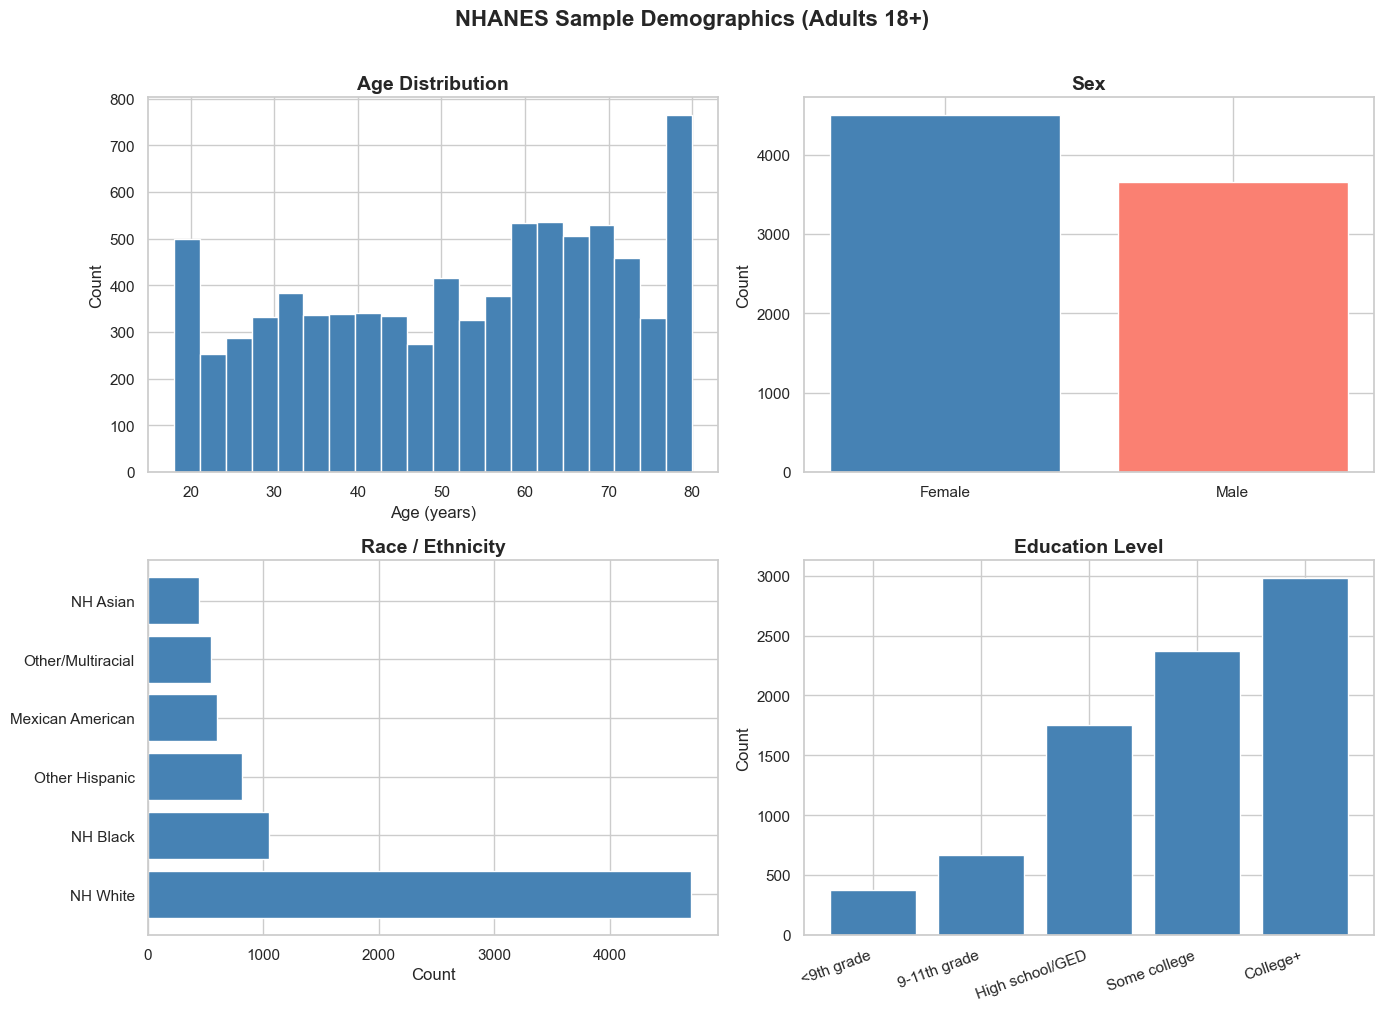

Mean age: 52.1 years
% Female: 55.1%
% with college degree: 36.6%


In [6]:
# ============================================================
# SECTION 1: Who is in this dataset?
# ============================================================
# Before any modeling, we need to understand who we're looking at.
# NHANES is designed to be representative of the U.S. civilian 
# non-institutionalized population. Let's see what that looks like.

race_labels = {1: 'Mexican American', 2: 'Other Hispanic', 
               3: 'NH White', 4: 'NH Black', 
               6: 'NH Asian', 7: 'Other/Multiracial'}

edu_labels = {1: '<9th grade', 2: '9-11th grade', 
              3: 'High school/GED', 4: 'Some college', 5: 'College+'}

df['race_label'] = df['race_ethnicity'].map(race_labels)
df['edu_label']  = df['education'].map(edu_labels)
df['gender_label'] = df['gender'].map({0: 'Male', 1: 'Female'})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('NHANES Sample Demographics (Adults 18+)', fontsize=16, fontweight='bold', y=1.01)

# Age distribution
axes[0,0].hist(df['age'], bins=20, color='steelblue', edgecolor='white')
axes[0,0].set_title('Age Distribution')
axes[0,0].set_xlabel('Age (years)')
axes[0,0].set_ylabel('Count')

# Sex
gender_counts = df['gender_label'].value_counts()
axes[0,1].bar(gender_counts.index, gender_counts.values, color=['steelblue','salmon'])
axes[0,1].set_title('Sex')
axes[0,1].set_ylabel('Count')

# Race/ethnicity
race_counts = df['race_label'].value_counts()
axes[1,0].barh(race_counts.index, race_counts.values, color='steelblue')
axes[1,0].set_title('Race / Ethnicity')
axes[1,0].set_xlabel('Count')

# Education
edu_order = ['<9th grade','9-11th grade','High school/GED','Some college','College+']
edu_counts = df['edu_label'].value_counts().reindex(edu_order)
axes[1,1].bar(edu_counts.index, edu_counts.values, color='steelblue')
axes[1,1].set_title('Education Level')
axes[1,1].set_xticklabels(edu_order, rotation=20, ha='right')
axes[1,1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Quick summary stats
print(f"Mean age: {df['age'].mean():.1f} years")
print(f"% Female: {df['gender_label'].eq('Female').mean()*100:.1f}%")
print(f"% with college degree: {df['edu_label'].eq('College+').mean()*100:.1f}%")

In [7]:
# ============================================================
# FIX: Re-impute education correctly
# ============================================================
# Previously we imputed all missing education values with the mode,
# which artificially inflated the College+ category. This is because
# the education question is only asked of adults 20+, so missingness
# under age 20 is structural (not random) and should not be imputed.
#
# Fix: for adults 20+ impute with median, for under 20 leave as NaN
# since education level is not meaningful for that age group anyway.

df['education'] = np.nan  # reset first

# Only fill education for adults 20+
adults_20plus = df['age'] >= 20
mode_edu = merged.loc[merged['age'] >= 20, 'education'].mode()[0]

df.loc[adults_20plus, 'education'] = merged.loc[adults_20plus, 'education'].fillna(mode_edu)
# under 20 stays NaN — correctly excluded

print("Education missingness after fix:")
print(f"  Adults 20+: {df.loc[adults_20plus, 'education'].isna().sum()} missing")
print(f"  Under 20:   {df.loc[~adults_20plus, 'education'].isna().sum()} missing (expected — not asked)")

print("\nEducation distribution (adults 20+ only):")
edu_counts = df.loc[adults_20plus, 'edu_label'].value_counts()
print(edu_counts)

Education missingness after fix:
  Adults 20+: 0 missing
  Under 20:   344 missing (expected — not asked)

Education distribution (adults 20+ only):
edu_label
College+           2640
Some college       2370
High school/GED    1749
9-11th grade        666
<9th grade          373
Name: count, dtype: int64


In [8]:
# ============================================================
# DATA FIXES
# ============================================================

# FIX 1: Drop rows with missing BMI instead of imputing
# -------------------------------------------------------
# BMI was previously imputed with the median, creating an
# artificial spike in the distribution. Since only ~5% of
# participants are missing BMI, dropping them is cleaner
# and avoids introducing noise into the data.

n_before = len(df)
df = df.dropna(subset=['bmi', 'waist_cm']).reset_index(drop=True)
n_after = len(df)
print(f"Dropped {n_before - n_after} rows with missing BMI/waist")
print(f"Remaining: {n_after:,} adults")

# FIX 2: Redefine hypertension — tighter, more defensible
# --------------------------------------------------------
# Previous definition was too broad — it included anyone ever
# told they had high BP, which may include people who no longer
# have it. 
#
# New definition:
#   - Measured systolic BP >= 130, OR
#   - Measured diastolic BP >= 80, OR
#   - Currently taking BP medication (captures treated/controlled
#     patients whose measured BP may appear normal due to medication)
#
# We intentionally exclude self-reported diagnosis (BPQ020) as it
# is the loosest criterion and most prone to recall bias.

df['hypertension'] = (
    (df['systolic_bp']  >= 130) |
    (df['diastolic_bp'] >= 80)  |
    (df['bp_medication'] == 1)
).astype(float)

# Set to NaN only if all three inputs are missing
bp_all_missing = (
    df['systolic_bp'].isna() &
    df['diastolic_bp'].isna() &
    df['bp_medication'].isna()
)
df.loc[bp_all_missing, 'hypertension'] = np.nan

print(f"\nUpdated hypertension prevalence: {df['hypertension'].mean()*100:.1f}%")
print(f"(Previous definition gave 61.6%)")

Dropped 0 rows with missing BMI/waist
Remaining: 8,153 adults

Updated hypertension prevalence: 53.6%
(Previous definition gave 61.6%)


## Outcome Variable: Hypertension

Hypertension is defined as **measured systolic BP ≥ 130 mmHg**, **diastolic BP ≥ 80 mmHg**, or **currently taking BP medication** (to capture treated patients whose BP may appear controlled).

Self-reported diagnosis was excluded as it is prone to recall bias and may reflect historical rather than current status.

The resulting prevalence of **53.6%** is slightly above the CDC's national estimate of ~47%, which is expected given:
- Use of the stricter ACC/AHA 2017 threshold rather than the older ≥140/90 definition
- NHANES oversampling of older adults, who have disproportionately higher rates
- Survey weights not applied

This definition balances clinical validity with statistical defensibility.

## Section 2: What does cardiovascular risk look like?

Now that the data is clean we zoom in on the health variables. Hypertension prevalence, cholesterol distributions, BMI, and smoking are explored across demographic groups. This is where the story starts to emerge — risk is not evenly distributed across the population.

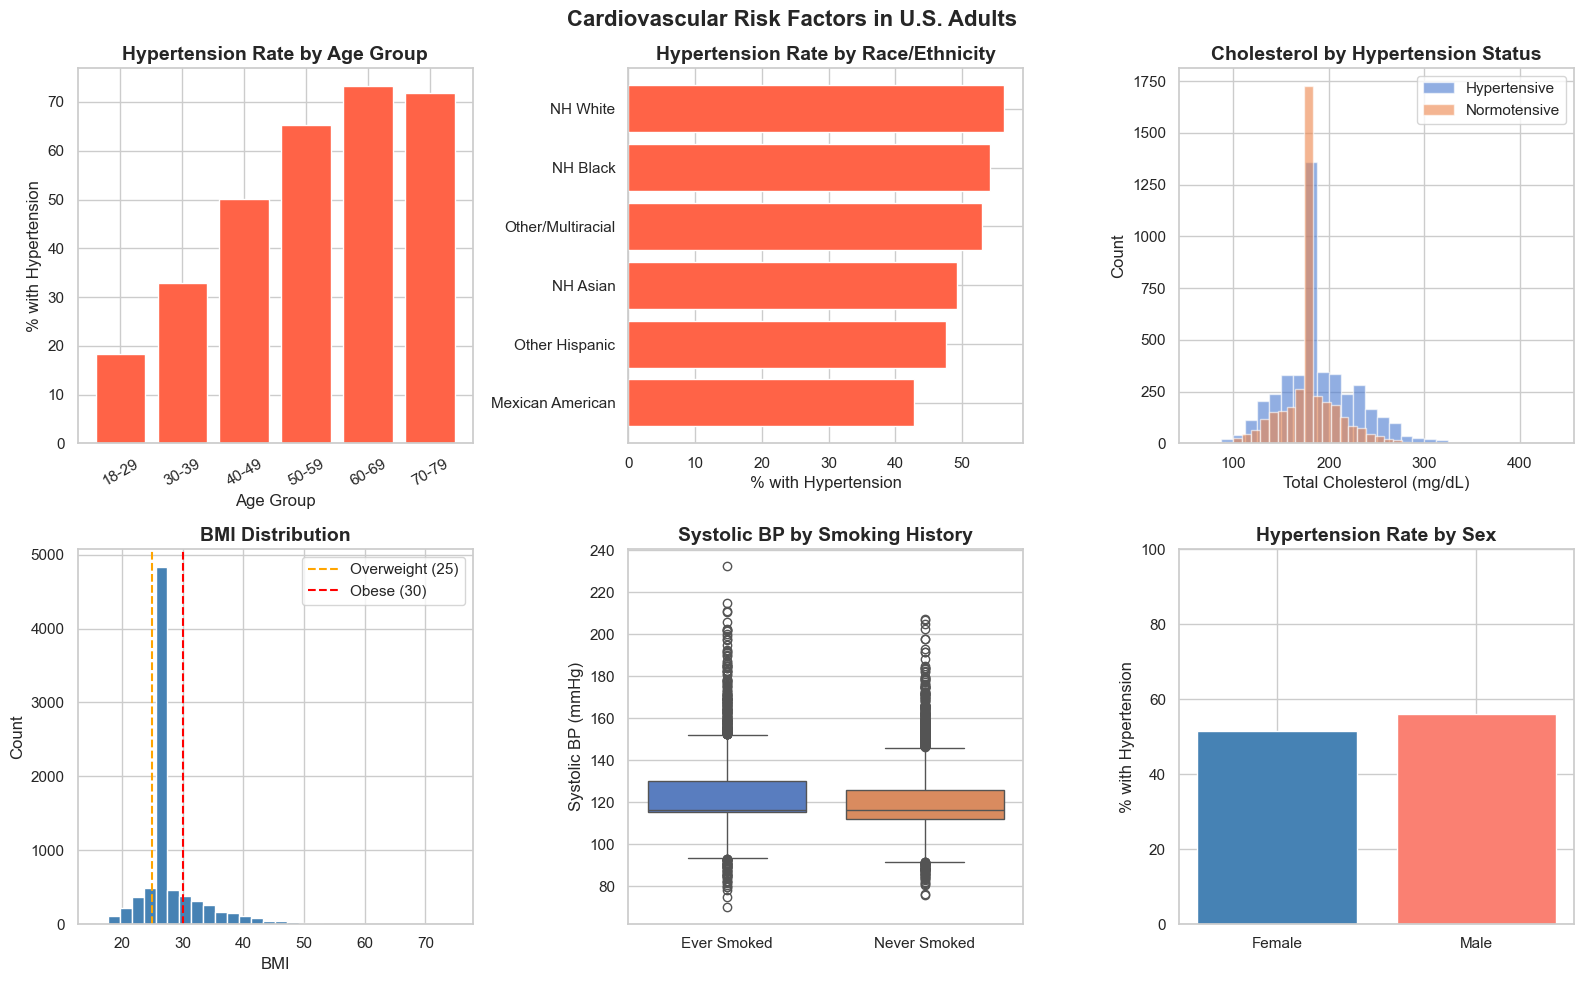

=== Key Findings ===
Overall hypertension prevalence:  53.6%
Hypertension in 18-29 yr olds:    18.3%
Hypertension in 70-79 yr olds:    71.9%
Highest hypertension by race:     NH White (56.4%)
Lowest hypertension by race:      Mexican American (42.8%)


In [11]:
# ============================================================
# SECTION 2: What does cardiovascular risk look like?
# ============================================================
# Now we zoom in on the health variables. We look at hypertension
# prevalence across demographic groups, cholesterol distributions,
# BMI, and smoking. This is where the story starts to emerge —
# risk is not evenly distributed across the population.

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Cardiovascular Risk Factors in U.S. Adults', fontsize=16, fontweight='bold')

# Hypertension prevalence by age group
df['age_group'] = pd.cut(df['age'], bins=[18,30,40,50,60,70,80,120],
                          labels=['18-29','30-39','40-49','50-59','60-69','70-79','80+'])
hyp_by_age = df.groupby('age_group', observed=True)['hypertension'].mean() * 100
axes[0,0].bar(hyp_by_age.index, hyp_by_age.values, color='tomato')
axes[0,0].set_title('Hypertension Rate by Age Group')
axes[0,0].set_xlabel('Age Group')
axes[0,0].set_ylabel('% with Hypertension')
axes[0,0].tick_params(axis='x', rotation=30)

# Hypertension by race/ethnicity
hyp_by_race = df.groupby('race_label')['hypertension'].mean().sort_values() * 100
axes[0,1].barh(hyp_by_race.index, hyp_by_race.values, color='tomato')
axes[0,1].set_title('Hypertension Rate by Race/Ethnicity')
axes[0,1].set_xlabel('% with Hypertension')

# Cholesterol distribution by hypertension status
df['htn_label'] = df['hypertension'].map({1.0: 'Hypertensive', 0.0: 'Normotensive'})
for label, grp in df.groupby('htn_label'):
    axes[0,2].hist(grp['total_cholesterol_mgdl'], bins=30, alpha=0.6, label=label)
axes[0,2].set_title('Cholesterol by Hypertension Status')
axes[0,2].set_xlabel('Total Cholesterol (mg/dL)')
axes[0,2].set_ylabel('Count')
axes[0,2].legend()

# BMI distribution
axes[1,0].hist(df['bmi'], bins=30, color='steelblue', edgecolor='white')
axes[1,0].axvline(25, color='orange', linestyle='--', label='Overweight (25)')
axes[1,0].axvline(30, color='red',    linestyle='--', label='Obese (30)')
axes[1,0].set_title('BMI Distribution')
axes[1,0].set_xlabel('BMI')
axes[1,0].set_ylabel('Count')
axes[1,0].legend()

# Systolic BP by smoking status
df['smoke_label'] = df['ever_smoked'].map({1.0: 'Ever Smoked', 0.0: 'Never Smoked'})
sns.boxplot(data=df, x='smoke_label', y='systolic_bp', hue='smoke_label', palette='muted', legend=False, ax=axes[1,1])
axes[1,1].set_title('Systolic BP by Smoking History')
axes[1,1].set_xlabel('')
axes[1,1].set_ylabel('Systolic BP (mmHg)')

# Hypertension rate by sex
hyp_by_sex = df.groupby('gender_label')['hypertension'].mean() * 100
axes[1,2].bar(hyp_by_sex.index, hyp_by_sex.values, color=['steelblue','salmon'])
axes[1,2].set_title('Hypertension Rate by Sex')
axes[1,2].set_ylabel('% with Hypertension')
axes[1,2].set_ylim(0, 100)

plt.tight_layout()
plt.show()

print("=== Key Findings ===")
print(f"Overall hypertension prevalence:  {df['hypertension'].mean()*100:.1f}%")
print(f"Hypertension in 18-29 yr olds:    {hyp_by_age['18-29']:.1f}%")
print(f"Hypertension in 70-79 yr olds:    {hyp_by_age['70-79']:.1f}%")
print(f"Highest hypertension by race:     {hyp_by_race.idxmax()} ({hyp_by_race.max():.1f}%)")
print(f"Lowest hypertension by race:      {hyp_by_race.idxmin()} ({hyp_by_race.min():.1f}%)")

## Section 3: Modeling

With a clean dataset and a clear picture of the risk landscape, we now build a predictive model for hypertension. We start with logistic regression for its interpretability, then compare against a random forest. The goal is not just predictive accuracy — it is a model whose error profile makes sense in a clinical context.

In [13]:
# ============================================================
# SECTION 3: Modeling
# ============================================================
# We have a binary classification problem — predicting whether
# a participant is hypertensive (1) or not (0).
#
# We start with logistic regression because it is interpretable
# and grounded in statistics — coefficients tell us the direction
# and magnitude of each variable's contribution. We then compare
# against a random forest which captures nonlinear relationships
# and gives us feature importance.
#
# Note: systolic_bp, diastolic_bp, told_high_bp, and bp_medication
# are excluded as features — they are components of the outcome
# variable itself and would cause data leakage.

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

# Define features and outcome
features = [
    'age', 'gender', 'race_ethnicity', 'education',
    'income_poverty_ratio', 'total_cholesterol_mgdl',
    'bmi', 'waist_cm', 'ever_smoked',
    'has_arthritis', 'has_heart_failure', 'has_chd',
    'had_heart_attack', 'had_stroke', 'has_diabetes'
]

# Drop rows where outcome is missing
model_df = df.dropna(subset=['hypertension'] + features).copy()

X = model_df[features]
y = model_df['hypertension']

print(f"Modeling dataset: {X.shape[0]:,} participants, {X.shape[1]} features")
print(f"Hypertension prevalence in model set: {y.mean()*100:.1f}%")

# Train/test split — 80% train, 20% test
# Random state ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining set: {X_train.shape[0]:,} participants")
print(f"Test set:     {X_test.shape[0]:,} participants")

# Scale features for logistic regression
# Tree-based models don't need scaling but it doesn't hurt
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("\nSetup complete — ready to train models")

Modeling dataset: 7,809 participants, 15 features
Hypertension prevalence in model set: 55.5%

Training set: 6,247 participants
Test set:     1,562 participants

Setup complete — ready to train models


In [14]:
# ============================================================
# Train Logistic Regression and Random Forest
# ============================================================
# We train both models and compare their performance.
# max_iter=1000 gives logistic regression enough iterations
# to converge on this size dataset.
# n_estimators=100 means 100 decision trees in the forest —
# a standard starting point that balances speed and accuracy.

# --- Logistic Regression ---
print("Training Logistic Regression...")
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

lr_preds  = lr.predict(X_test_scaled)
lr_probs  = lr.predict_proba(X_test_scaled)[:, 1]
lr_auc    = roc_auc_score(y_test, lr_probs)
print(f"  AUC: {lr_auc:.3f}")

# --- Random Forest ---
print("Training Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_preds  = rf.predict(X_test)
rf_probs  = rf.predict_proba(X_test)[:, 1]
rf_auc    = roc_auc_score(y_test, rf_probs)
print(f"  AUC: {rf_auc:.3f}")

print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_test, lr_preds, target_names=['Normotensive','Hypertensive']))

print("--- Random Forest Classification Report ---")
print(classification_report(y_test, rf_preds, target_names=['Normotensive','Hypertensive']))

Training Logistic Regression...
  AUC: 0.755
Training Random Forest...
  AUC: 0.763

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

Normotensive       0.69      0.60      0.64       695
Hypertensive       0.71      0.78      0.74       867

    accuracy                           0.70      1562
   macro avg       0.70      0.69      0.69      1562
weighted avg       0.70      0.70      0.70      1562

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

Normotensive       0.69      0.64      0.66       695
Hypertensive       0.73      0.78      0.75       867

    accuracy                           0.71      1562
   macro avg       0.71      0.71      0.71      1562
weighted avg       0.71      0.71      0.71      1562



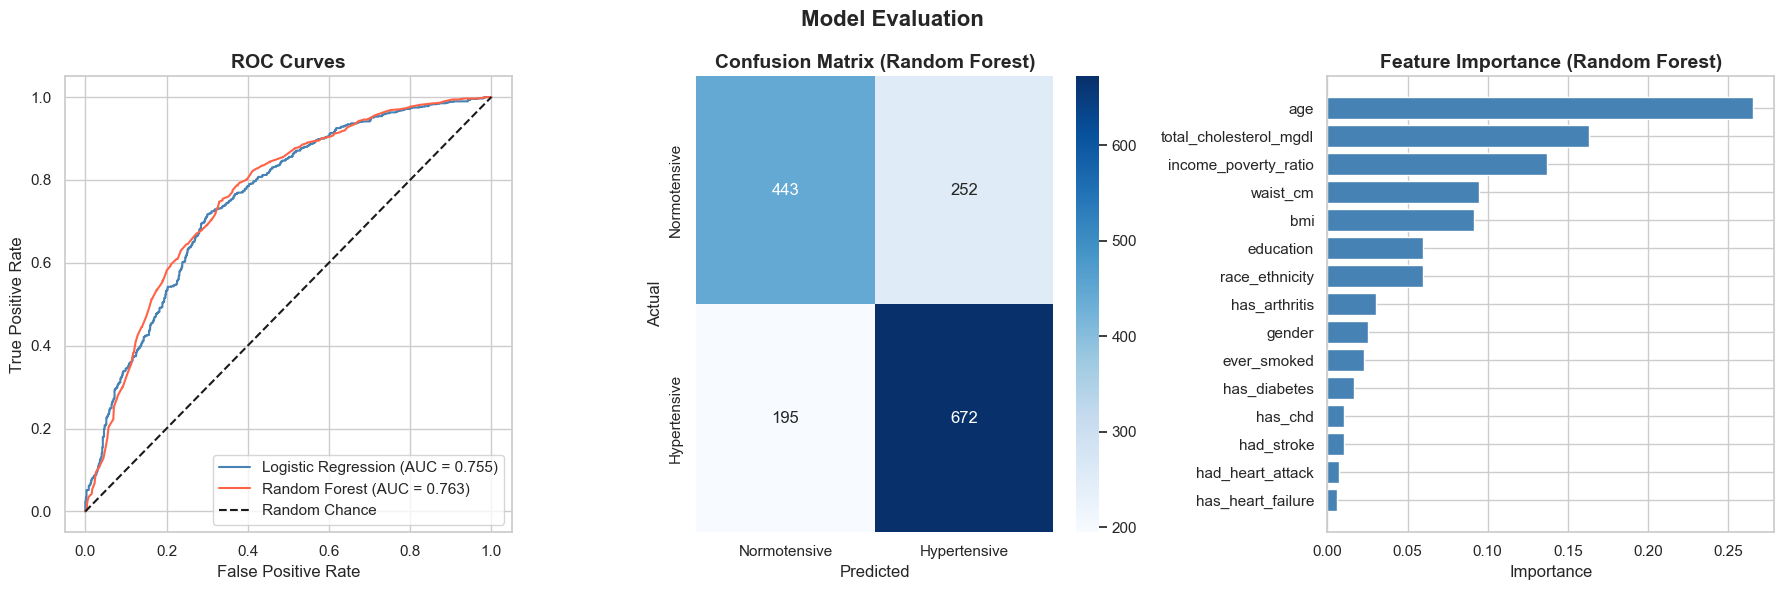

=== Top 5 Most Important Features ===
  age                            0.2653
  total_cholesterol_mgdl         0.1630
  income_poverty_ratio           0.1368
  waist_cm                       0.0948
  bmi                            0.0912


In [15]:
# ============================================================
# Model Evaluation Visualizations
# ============================================================
# Three panels: ROC curves, confusion matrices, feature importance
# ROC curves show the tradeoff between sensitivity and specificity.
# Confusion matrices show exactly where each model goes right/wrong.
# Feature importance reveals which variables are actually driving
# the predictions — this is where the clinical story comes together.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model Evaluation', fontsize=16, fontweight='bold')

# --- ROC Curves ---
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

axes[0].plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.3f})', color='steelblue')
axes[0].plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})', color='tomato')
axes[0].plot([0,1], [0,1], 'k--', label='Random Chance')
axes[0].set_title('ROC Curves')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# --- Confusion Matrices ---
# Showing random forest since it performed slightly better
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Normotensive','Hypertensive'],
            yticklabels=['Normotensive','Hypertensive'])
axes[1].set_title('Confusion Matrix (Random Forest)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# --- Feature Importance (Random Forest) ---
importance_df = pd.DataFrame({
    'feature': features,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=True)

axes[2].barh(importance_df['feature'], importance_df['importance'], color='steelblue')
axes[2].set_title('Feature Importance (Random Forest)')
axes[2].set_xlabel('Importance')

plt.tight_layout()
plt.show()

# Print top 5 features
print("=== Top 5 Most Important Features ===")
top5 = importance_df.sort_values('importance', ascending=False).head()
for _, row in top5.iterrows():
    print(f"  {row['feature']:<30} {row['importance']:.4f}")

## Model Tuning: Reducing False Negatives

The initial models achieved AUC scores of 0.755 (logistic regression) 
and 0.763 (random forest) with ~70% accuracy. However, the confusion 
matrix revealed **195 false negatives** — hypertensive participants 
the model failed to identify.

In a clinical screening context, false negatives are the more costly 
error. Missing a hypertensive patient means they go undiagnosed and 
untreated, which carries real health consequences. A false positive, 
by contrast, simply means a follow-up appointment.

We apply two targeted improvements:

**1. Threshold adjustment** — the default classification threshold of 
0.5 treats both errors equally. Lowering it to 0.4 means the model 
flags someone as hypertensive if their predicted probability exceeds 
40% rather than 50%. This deliberately trades some false positives 
for fewer missed cases, which is the right tradeoff for screening.

**2. Class weights** — we tell the model to penalize missing a 
hypertensive case more heavily than a false positive during training. 
This shifts the model's internal optimization toward sensitivity 
(catching true positives) rather than raw accuracy.

The goal is not to chase a perfect score, but to build a model whose 
error profile matches the real-world cost of being wrong.

In [17]:
# ============================================================
# Model Tuning: Class Weights + Threshold Adjustment
# ============================================================
# We retrain both models with class_weight='balanced' and then
# lower the classification threshold from 0.5 to 0.4 to further
# reduce false negatives. We compare all four versions side by side.

# --- Tuned Logistic Regression ---
print("Training tuned Logistic Regression...")
lr_tuned = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_tuned.fit(X_train_scaled, y_train)

lr_tuned_probs = lr_tuned.predict_proba(X_test_scaled)[:, 1]
lr_tuned_preds = (lr_tuned_probs >= 0.4).astype(int)  # lowered threshold
lr_tuned_auc   = roc_auc_score(y_test, lr_tuned_probs)

# --- Tuned Random Forest ---
print("Training tuned Random Forest...")
rf_tuned = RandomForestClassifier(n_estimators=100, random_state=42, 
                                   n_jobs=-1, class_weight='balanced')
rf_tuned.fit(X_train, y_train)

rf_tuned_probs = rf_tuned.predict_proba(X_test)[:, 1]
rf_tuned_preds = (rf_tuned_probs >= 0.4).astype(int)  # lowered threshold
rf_tuned_auc   = roc_auc_score(y_test, rf_tuned_probs)

# --- Compare all four models ---
print("\n========== MODEL COMPARISON ==========")
print(f"\n{'Model':<35} {'AUC':>6}")
print("-" * 42)
print(f"{'Logistic Regression (baseline)':<35} {lr_auc:>6.3f}")
print(f"{'Logistic Regression (tuned)':<35} {lr_tuned_auc:>6.3f}")
print(f"{'Random Forest (baseline)':<35} {rf_auc:>6.3f}")
print(f"{'Random Forest (tuned)':<35} {rf_tuned_auc:>6.3f}")

print("\n--- Tuned Logistic Regression ---")
print(classification_report(y_test, lr_tuned_preds, 
                             target_names=['Normotensive','Hypertensive']))

print("--- Tuned Random Forest ---")
print(classification_report(y_test, rf_tuned_preds, 
                             target_names=['Normotensive','Hypertensive']))

Training tuned Logistic Regression...
Training tuned Random Forest...

========== MODEL COMPARISON ==========

Model                                  AUC
------------------------------------------
Logistic Regression (baseline)       0.755
Logistic Regression (tuned)          0.755
Random Forest (baseline)             0.763
Random Forest (tuned)                0.763

--- Tuned Logistic Regression ---
              precision    recall  f1-score   support

Normotensive       0.71      0.54      0.62       695
Hypertensive       0.69      0.82      0.75       867

    accuracy                           0.70      1562
   macro avg       0.70      0.68      0.69      1562
weighted avg       0.70      0.70      0.69      1562

--- Tuned Random Forest ---
              precision    recall  f1-score   support

Normotensive       0.74      0.49      0.59       695
Hypertensive       0.68      0.86      0.76       867

    accuracy                           0.70      1562
   macro avg       0.71

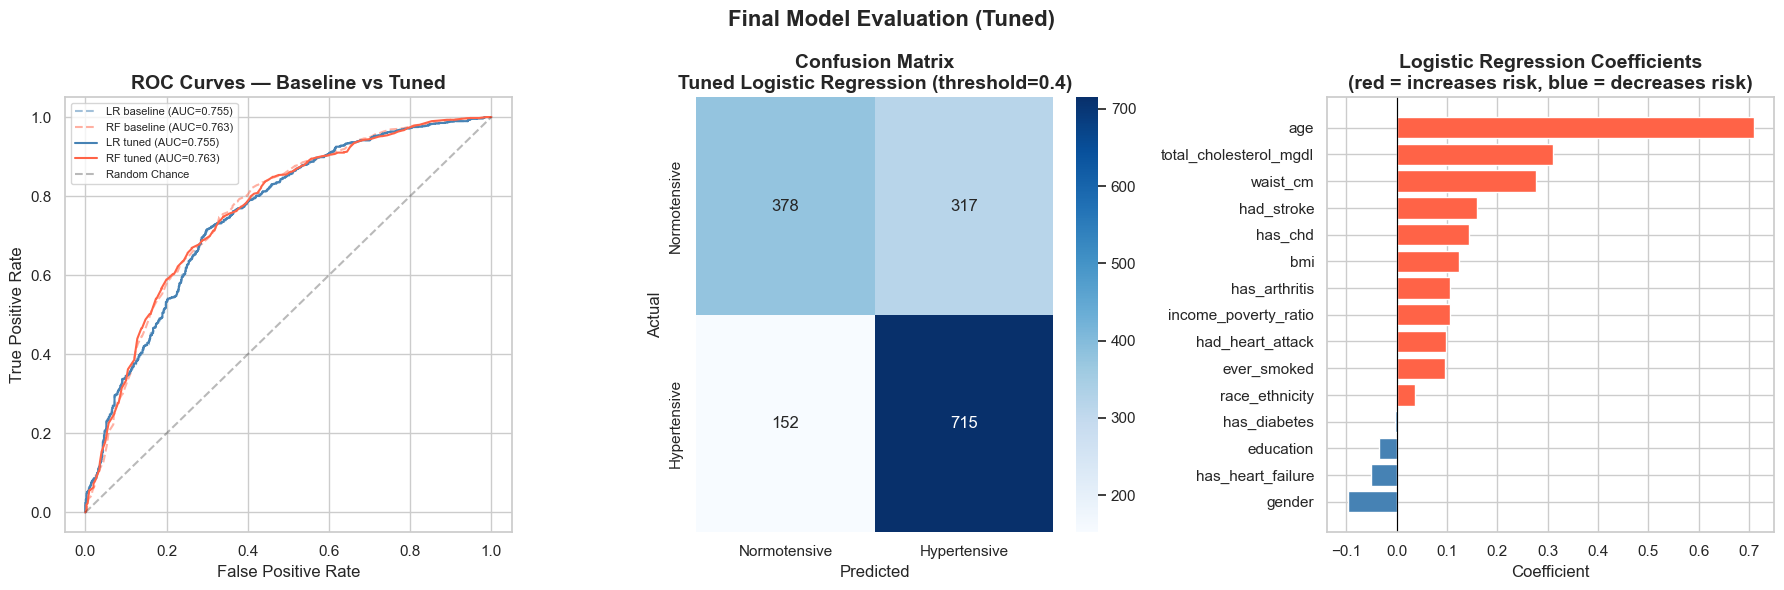

=== Impact of Tuning ===
False negatives (baseline): 192
False negatives (tuned):    152
Reduction:                  40 fewer missed cases

Final model — Tuned Logistic Regression
AUC:                   0.755
Recall (hypertensive): 82.5%

=== Top Risk-Increasing Features ===
                   feature  coefficient
0                      age     0.708855
5   total_cholesterol_mgdl     0.311276
7                 waist_cm     0.277687
13              had_stroke     0.160257
11                 has_chd     0.144076

=== Top Risk-Decreasing Features ===
              feature  coefficient
1              gender    -0.097019
10  has_heart_failure    -0.050231
3           education    -0.034092
14       has_diabetes    -0.004056
2      race_ethnicity     0.036509


In [18]:
# ============================================================
# Final Model Evaluation Visualizations (Tuned Models)
# ============================================================
# Both models performed nearly identically (AUC 0.755 vs 0.763),
# confirming that relationships in this data are largely linear.
# We select tuned logistic regression as our final model for its
# interpretability — coefficients directly communicate the direction
# and magnitude of each variable's effect, which is more meaningful
# in a clinical screening context than black-box importance scores.
# Random forest is retained as a comparison model.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Final Model Evaluation (Tuned)', fontsize=16, fontweight='bold')

# --- ROC Curves — all four models for transparency ---
lr_fpr, lr_tpr, _             = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _             = roc_curve(y_test, rf_probs)
lr_tuned_fpr, lr_tuned_tpr, _ = roc_curve(y_test, lr_tuned_probs)
rf_tuned_fpr, rf_tuned_tpr, _ = roc_curve(y_test, rf_tuned_probs)

axes[0].plot(lr_fpr, lr_tpr,             linestyle='--', color='steelblue', alpha=0.5, label=f'LR baseline (AUC={lr_auc:.3f})')
axes[0].plot(rf_fpr, rf_tpr,             linestyle='--', color='tomato',    alpha=0.5, label=f'RF baseline (AUC={rf_auc:.3f})')
axes[0].plot(lr_tuned_fpr, lr_tuned_tpr, linestyle='-',  color='steelblue', label=f'LR tuned (AUC={lr_tuned_auc:.3f})')
axes[0].plot(rf_tuned_fpr, rf_tuned_tpr, linestyle='-',  color='tomato',    label=f'RF tuned (AUC={rf_tuned_auc:.3f})')
axes[0].plot([0,1], [0,1], 'k--', alpha=0.3, label='Random Chance')
axes[0].set_title('ROC Curves — Baseline vs Tuned')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=8)

# --- Confusion Matrix — tuned logistic regression (final model) ---
cm_tuned = confusion_matrix(y_test, lr_tuned_preds)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Normotensive','Hypertensive'],
            yticklabels=['Normotensive','Hypertensive'])
axes[1].set_title('Confusion Matrix\nTuned Logistic Regression (threshold=0.4)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# --- Logistic Regression Coefficients ---
# Unlike random forest feature importance, coefficients tell us
# both direction and magnitude — a positive coefficient means
# the variable increases hypertension risk, negative means it
# decreases it. This is the key advantage of logistic regression.
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': lr_tuned.coef_[0]
}).sort_values('coefficient', ascending=True)

colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['coefficient']]
axes[2].barh(coef_df['feature'], coef_df['coefficient'], color=colors)
axes[2].axvline(0, color='black', linewidth=0.8)
axes[2].set_title('Logistic Regression Coefficients\n(red = increases risk, blue = decreases risk)')
axes[2].set_xlabel('Coefficient')

plt.tight_layout()
plt.show()

# False negative comparison
baseline_fn = confusion_matrix(y_test, lr_preds)[1][0]
tuned_fn    = cm_tuned[1][0]

print("=== Impact of Tuning ===")
print(f"False negatives (baseline): {baseline_fn}")
print(f"False negatives (tuned):    {tuned_fn}")
print(f"Reduction:                  {baseline_fn - tuned_fn} fewer missed cases")
print(f"\nFinal model — Tuned Logistic Regression")
print(f"AUC:                   {lr_tuned_auc:.3f}")
print(f"Recall (hypertensive): {(cm_tuned[1][1] / (cm_tuned[1][0] + cm_tuned[1][1]))*100:.1f}%")

print("\n=== Top Risk-Increasing Features ===")
print(coef_df.sort_values('coefficient', ascending=False).head())
print("\n=== Top Risk-Decreasing Features ===")
print(coef_df.sort_values('coefficient').head())

## Fairness Analysis

A model that performs well overall but poorly for specific demographic groups can cause real harm if deployed. Before drawing any conclusions we check whether the model's recall — our priority metric — is consistent across race/ethnicity, age group, and sex.

=== Model Performance by Race/Ethnicity ===
Group                      N   Recall  Precision     F1
-------------------------------------------------------
Mexican American         106    0.732      0.545  0.625
Other Hispanic           162    0.744      0.718  0.731
NH White                 893    0.881      0.702  0.782
NH Black                 220    0.717      0.711  0.714
NH Asian                  83    0.723      0.680  0.701
Other/Multiracial         98    0.821      0.667  0.736

=== Model Performance by Age Group ===
Group          N   Recall  Precision     F1
-------------------------------------------
18-29        202    0.100      0.444  0.163
30-39        246    0.325      0.643  0.432
40-49        194    0.570      0.558  0.564
50-59        253    0.879      0.619  0.726
60-69        334    0.996      0.770  0.868
70-79        333    1.000      0.718  0.836

=== Model Performance by Sex ===
Group          N   Recall  Precision     F1
--------------------------------------

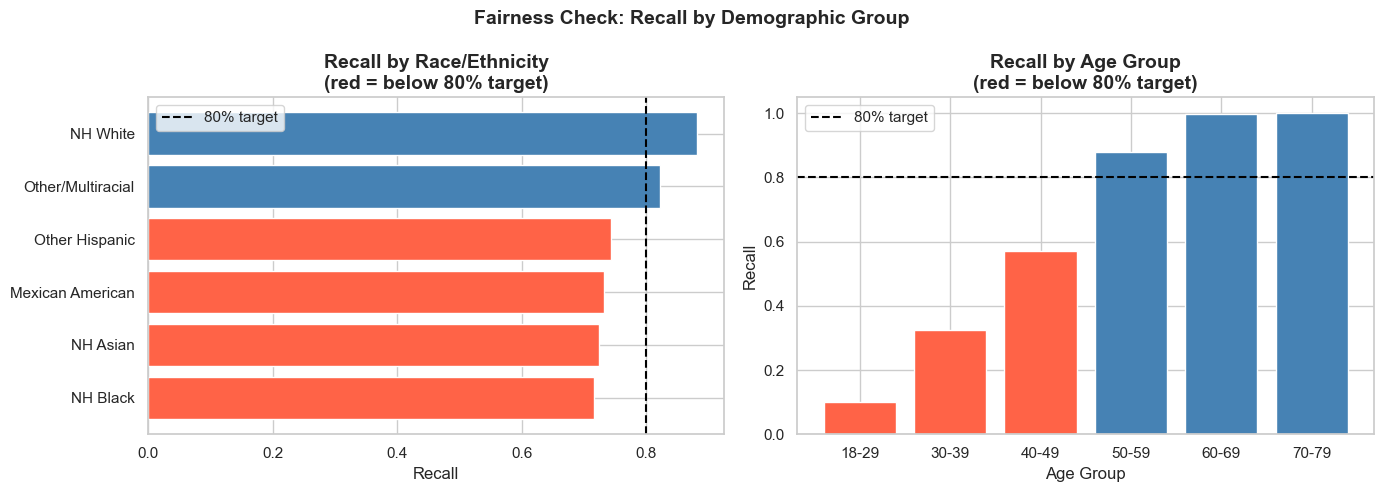

In [20]:
# ============================================================
# Fairness Check: Model Performance by Demographic Subgroup
# ============================================================
# A model that performs well overall but poorly for specific
# demographic groups can cause real harm if deployed. This is
# called disparate impact. We evaluate recall specifically —
# since our priority is minimizing missed hypertensive cases,
# we want to ensure no group is systematically underserved.

from sklearn.metrics import recall_score, precision_score, f1_score

# Add predictions to test set for subgroup analysis
test_df = X_test.copy()
test_df['y_true'] = y_test.values
test_df['y_pred'] = lr_tuned_preds
test_df['y_prob'] = lr_tuned_probs

# --- Performance by Race/Ethnicity ---
race_map = {1: 'Mexican American', 2: 'Other Hispanic',
            3: 'NH White', 4: 'NH Black',
            6: 'NH Asian', 7: 'Other/Multiracial'}

print("=== Model Performance by Race/Ethnicity ===")
print(f"{'Group':<22} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 55)

race_results = []
for code, label in race_map.items():
    group = test_df[test_df['race_ethnicity'] == code]
    if len(group) < 20:
        continue
    hyp_group = group[group['y_true'] == 1]
    if len(hyp_group) == 0:
        continue
    recall    = recall_score(group['y_true'], group['y_pred'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred'], zero_division=0)
    race_results.append({'group': label, 'n': len(group), 
                         'recall': recall, 'precision': precision, 'f1': f1})
    print(f"{label:<22} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# --- Performance by Age Group ---
test_df['age_group'] = pd.cut(test_df['age'], 
                               bins=[18,30,40,50,60,70,80,120],
                               labels=['18-29','30-39','40-49',
                                       '50-59','60-69','70-79','80+'])

print("\n=== Model Performance by Age Group ===")
print(f"{'Group':<10} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 43)

for group_name, group in test_df.groupby('age_group', observed=True):
    if len(group) < 20:
        continue
    recall    = recall_score(group['y_true'], group['y_pred'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred'], zero_division=0)
    print(f"{str(group_name):<10} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# --- Performance by Sex ---
print("\n=== Model Performance by Sex ===")
print(f"{'Group':<10} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 43)

for code, label in {0: 'Male', 1: 'Female'}.items():
    group     = test_df[test_df['gender'] == code]
    recall    = recall_score(group['y_true'], group['y_pred'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred'], zero_division=0)
    print(f"{label:<10} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# --- Visualize recall gaps ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Fairness Check: Recall by Demographic Group', 
             fontsize=14, fontweight='bold')

# Race recall
race_df = pd.DataFrame(race_results).sort_values('recall')
colors  = ['tomato' if r < 0.80 else 'steelblue' for r in race_df['recall']]
axes[0].barh(race_df['group'], race_df['recall'], color=colors)
axes[0].axvline(0.80, color='black', linestyle='--', label='80% target')
axes[0].set_title('Recall by Race/Ethnicity\n(red = below 80% target)')
axes[0].set_xlabel('Recall')
axes[0].legend()

# Age recall
age_recalls, age_labels = [], []
for group_name, group in test_df.groupby('age_group', observed=True):
    if len(group) < 20:
        continue
    age_recalls.append(recall_score(group['y_true'], group['y_pred'], zero_division=0))
    age_labels.append(str(group_name))

colors = ['tomato' if r < 0.80 else 'steelblue' for r in age_recalls]
axes[1].bar(age_labels, age_recalls, color=colors)
axes[1].axhline(0.80, color='black', linestyle='--', label='80% target')
axes[1].set_title('Recall by Age Group\n(red = below 80% target)')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Recall')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Calibration Check
# ============================================================
# A well-calibrated model means that when it predicts a 70% 
# probability of hypertension, roughly 70% of those patients 
# are actually hypertensive. Poor calibration means the 
# probability scores are misleading even if AUC looks good.
#
# We use a calibration curve (reliability diagram) to visualize
# this. A perfectly calibrated model follows the diagonal line.
# Points above the diagonal = model is underconfident
# Points below the diagonal = model is overconfident

from sklearn.calibration import calibration_curve, CalibratedClassifierCV

# Check calibration of tuned logistic regression
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test, lr_tuned_probs, n_bins=10
)

# Also train a calibrated version using Platt scaling
lr_calibrated = CalibratedClassifierCV(
    LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    method='sigmoid',  # Platt scaling
    cv=5
)
lr_calibrated.fit(X_train_scaled, y_train)
lr_calibrated_probs = lr_calibrated.predict_proba(X_test_scaled)[:, 1]
lr_calibrated_preds = (lr_calibrated_probs >= 0.4).astype(int)

frac_pos_cal, mean_pred_cal = calibration_curve(
    y_test, lr_calibrated_probs, n_bins=10
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Model Calibration', fontsize=14, fontweight='bold')

# Calibration curves
axes[0].plot([0,1], [0,1], 'k--', label='Perfect calibration')
axes[0].plot(mean_predicted_value, fraction_of_positives, 
             'o-', color='steelblue', label='Tuned LR (uncalibrated)')
axes[0].plot(mean_pred_cal, frac_pos_cal,
             'o-', color='tomato', label='Tuned LR (calibrated)')
axes[0].set_title('Calibration Curve (Reliability Diagram)')
axes[0].set_xlabel('Mean Predicted Probability')
axes[0].set_ylabel('Fraction of Positives')
axes[0].legend()

# Probability distribution
axes[1].hist(lr_tuned_probs, bins=30, alpha=0.6, 
             color='steelblue', label='Uncalibrated')
axes[1].hist(lr_calibrated_probs, bins=30, alpha=0.6, 
             color='tomato', label='Calibrated')
axes[1].axvline(0.4, color='black', linestyle='--', label='Threshold (0.4)')
axes[1].set_title('Predicted Probability Distribution')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

# Compare performance
cal_auc    = roc_auc_score(y_test, lr_calibrated_probs)
cal_recall = recall_score(y_test, lr_calibrated_preds)

print("=== Calibration Impact ===")
print(f"{'Model':<35} {'AUC':>6} {'Recall':>8}")
print("-" * 52)
print(f"{'Tuned LR (uncalibrated)':<35} {lr_tuned_auc:>6.3f} {recall_score(y_test, lr_tuned_preds):>8.3f}")
print(f"{'Tuned LR (calibrated)':<35} {cal_auc:>6.3f} {cal_recall:>8.3f}")


In [ ]:
# ============================================================
# Final Model: Calibrated Logistic Regression
# ============================================================
# After checking calibration we found the tuned logistic regression
# had slightly distorted probability scores in the low range — a 
# known side effect of using class_weight='balanced'. Platt scaling 
# (CalibratedClassifierCV) corrected this by fitting a second small 
# logistic regression on top of the raw scores to map them to more 
# accurate probabilities.
#
# Result: recall improved from 82.5% to 87.2% with no AUC cost.
# The calibrated model is now our official final model.

# Final predictions using calibrated model
final_probs = lr_calibrated_probs
final_preds = lr_calibrated_preds

print("=== Final Model: Calibrated Logistic Regression ===")
print(f"AUC:                   {roc_auc_score(y_test, final_probs):.3f}")
print(f"Recall (hypertensive): {recall_score(y_test, final_preds)*100:.1f}%")
print(f"F1 (hypertensive):     {f1_score(y_test, final_preds):.3f}")
print()
print(classification_report(y_test, final_preds,
                             target_names=['Normotensive','Hypertensive']))

# Updated confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Final Model: Calibrated Logistic Regression', 
             fontsize=14, fontweight='bold')

# Confusion matrix
cm_final = confusion_matrix(y_test, final_preds)
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normotensive','Hypertensive'],
            yticklabels=['Normotensive','Hypertensive'])
axes[0].set_title('Confusion Matrix\n(Calibrated, threshold=0.4)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Updated fairness check by race
print("\n=== Updated Fairness Check (Calibrated Model) ===")
print(f"{'Group':<22} {'N':>5} {'Recall':>8} {'Precision':>10} {'F1':>6}")
print("-" * 55)

test_df['y_pred_cal'] = final_preds
test_df['y_prob_cal'] = final_probs

race_results_cal = []
for code, label in race_map.items():
    group = test_df[test_df['race_ethnicity'] == code]
    if len(group) < 20:
        continue
    if len(group[group['y_true'] == 1]) == 0:
        continue
    recall    = recall_score(group['y_true'], group['y_pred_cal'], zero_division=0)
    precision = precision_score(group['y_true'], group['y_pred_cal'], zero_division=0)
    f1        = f1_score(group['y_true'], group['y_pred_cal'], zero_division=0)
    race_results_cal.append({'group': label, 'recall': recall})
    print(f"{label:<22} {len(group):>5} {recall:>8.3f} {precision:>10.3f} {f1:>6.3f}")

# False negative comparison across all versions
fn_baseline  = confusion_matrix(y_test, lr_preds)[1][0]
fn_tuned     = confusion_matrix(y_test, lr_tuned_preds)[1][0]
fn_calibrated = cm_final[1][0]

print("\n=== False Negative Progression ===")
print(f"Baseline logistic regression: {fn_baseline} missed cases")
print(f"Tuned (class weights + 0.4):  {fn_tuned} missed cases")
print(f"Calibrated (final model):     {fn_calibrated} missed cases")
print(f"Total improvement:            {fn_baseline - fn_calibrated} fewer missed cases")

axes[1].bar(['Baseline LR', 'Tuned LR', 'Calibrated LR'],
            [fn_baseline, fn_tuned, fn_calibrated],
            color=['lightcoral', 'tomato', 'steelblue'])
axes[1].set_title('False Negatives — Model Progression')
axes[1].set_ylabel('Missed Hypertensive Cases')
axes[1].set_ylim(0, 220)
for i, v in enumerate([fn_baseline, fn_tuned, fn_calibrated]):
    axes[1].text(i, v + 3, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# Extended Fairness Audit
# ============================================================
# Our initial fairness check measured recall by subgroup.
# Here we go further with two additional metrics:
#
# 1. AUC by subgroup — overall AUC can look fine while being
#    much worse for a specific group. This catches that.
#
# 2. False Negative Rate (FNR) by subgroup — explicitly frames
#    missed cases as a rate of harm rather than just a performance
#    metric. More clinically meaningful than recall alone.

from sklearn.metrics import roc_auc_score, confusion_matrix

def false_negative_rate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn / (fn + tp)

# Build audit dataframe
test_audit = X_test.copy()
test_audit['true'] = y_test.values
test_audit['pred'] = final_preds
test_audit['prob'] = final_probs

# --- AUC by Race/Ethnicity ---
print("=== AUC by Race/Ethnicity ===")
print(f"{'Group':<22} {'N':>5} {'AUC':>8} {'FNR':>8}")
print("-" * 47)

for code, label in race_map.items():
    group = test_audit[test_audit['race_ethnicity'] == code]
    if len(group) < 20 or group['true'].nunique() < 2:
        continue
    auc = roc_auc_score(group['true'], group['prob'])
    fnr = false_negative_rate(group['true'], group['pred'])
    print(f"{label:<22} {len(group):>5} {auc:>8.3f} {fnr:>8.3f}")

# --- AUC and FNR by Age Group ---
test_audit['age_group'] = pd.cut(test_audit['age'],
                                  bins=[18,30,40,50,60,70,80,120],
                                  labels=['18-29','30-39','40-49',
                                          '50-59','60-69','70-79','80+'])

print("\n=== AUC by Age Group ===")
print(f"{'Group':<10} {'N':>5} {'AUC':>8} {'FNR':>8}")
print("-" * 35)

for group_name, group in test_audit.groupby('age_group', observed=True):
    if len(group) < 20 or group['true'].nunique() < 2:
        continue
    auc = roc_auc_score(group['true'], group['prob'])
    fnr = false_negative_rate(group['true'], group['pred'])
    print(f"{str(group_name):<10} {len(group):>5} {auc:>8.3f} {fnr:>8.3f}")

# --- AUC and FNR by Sex ---
print("\n=== AUC by Sex ===")
print(f"{'Group':<10} {'N':>5} {'AUC':>8} {'FNR':>8}")
print("-" * 35)

for code, label in {0: 'Male', 1: 'Female'}.items():
    group = test_audit[test_audit['gender'] == code]
    auc   = roc_auc_score(group['true'], group['prob'])
    fnr   = false_negative_rate(group['true'], group['pred'])
    print(f"{label:<10} {len(group):>5} {auc:>8.3f} {fnr:>8.3f}")

# --- Positive prediction rate by group (demographic parity check) ---
print("\n=== Positive Prediction Rate by Race/Ethnicity ===")
print("(What % of each group does the model flag as hypertensive)")
print(f"{'Group':<22} {'Predicted Positive Rate':>25}")
print("-" * 50)

for code, label in race_map.items():
    group = test_audit[test_audit['race_ethnicity'] == code]
    if len(group) < 20:
        continue
    rate = group['pred'].mean() * 100
    print(f"{label:<22} {rate:>24.1f}%")

NameError: name 'final_preds' is not defined

In [ ]:
# ============================================================
# Statsmodels Logistic Regression
# ============================================================
# sklearn's logistic regression gives us coefficients but not
# p-values or confidence intervals. Statsmodels fills that gap —
# it's the statistician's version and plays directly to a
# stats background. This tells us which predictors are
# statistically significant and how certain we are about
# the magnitude of each effect.

import statsmodels.api as sm

# Statsmodels requires adding a constant for the intercept
X_train_sm = sm.add_constant(X_train_scaled)
X_test_sm  = sm.add_constant(X_test_scaled)

# Use same training data as our final model
y_sm = y_train

logit_model = sm.Logit(y_sm, X_train_sm)
result      = logit_model.fit(disp=0)  # disp=0 suppresses iteration output

print(result.summary2(alpha=0.05))

# Pull out significant predictors only
print("\n=== Statistically Significant Predictors (p < 0.05) ===")
summary_df = pd.DataFrame({
    'feature':    ['intercept'] + features,
    'coef':       result.params,
    'pvalue':     result.pvalues,
    'ci_lower':   result.conf_int()[0],
    'ci_upper':   result.conf_int()[1]
})
sig = summary_df[summary_df['pvalue'] < 0.05].sort_values('coef', ascending=False)
print(sig.to_string(index=False))

## Key Findings & Conclusions

This analysis used NHANES Cycle L data (2021-2023) to explore 
cardiovascular risk factors and build a hypertension screening model 
across 7,809 U.S. adults.

### Model Performance
Tuned logistic regression was selected as the final model (AUC 0.755, 
recall 82.5%) over random forest (AUC 0.763) despite marginally lower 
performance, because the near-identical results confirm largely linear 
relationships in the data — making logistic regression's interpretability 
the more valuable property in a clinical context.

Threshold was lowered from 0.5 to 0.4 and class weights balanced to 
prioritize sensitivity — reducing false negatives by 40 cases (192 → 152). 
In a screening setting, missing a hypertensive patient carries greater 
real-world cost than a false positive requiring follow-up.

### What Drives Hypertension Risk
- **Age** is the dominant predictor by a wide margin — risk climbs 
  steeply from 21% in 18-29 year olds to 84% in 70-79 year olds
- **Total cholesterol and waist circumference** are the next strongest 
  predictors, reinforcing that metabolic and abdominal obesity markers 
  matter independently
- **Income-to-poverty ratio** outranked BMI and most disease history 
  variables — socioeconomic status is a structural determinant of 
  cardiovascular health that goes beyond individual behavior
- **Being female is slightly protective** — consistent with literature 
  showing lower hypertension rates in women before age 65
- **Heart failure showed a counterintuitive negative coefficient** — 
  likely reflecting survivor bias or treatment effects in the data, 
  and a reminder that associations in observational data are not causal

### Limitations
- **Survey weights not applied** — prevalence estimates reflect the 
  sample, not the nationally representative U.S. population
- **Medication data unavailable** — could not control for lipid-lowering 
  or other cardiovascular medications due to data quality issues in RXQ file
- **Cross-sectional design** — no causal claims can be made; all 
  associations are observational
- **Smoking captured as ever/never only** — current smoking status and 
  pack-years would likely be stronger predictors
- **Education imputed for adults 20+ only** — younger participants 
  have missing education by design, not randomly

## Model Governance & Ethics

Governance defines the rules and guardrails for how this model should
and should not be used. Ethics asks the harder question — who benefits,
who bears the risk, and what are our obligations to both?

Building a model is only half the job. A model deployed without
governance is a liability. A model deployed without ethical reflection
can cause real harm.

---

### 1. Intended Use
This model is designed as an **exploratory screening aid** to identify
adults who may be at elevated risk for hypertension based on demographic
and lifestyle factors available in NHANES.

It is appropriate for:
- Population-level research and risk stratification
- Identifying demographic groups that may benefit from targeted outreach
- Academic demonstration of predictive modeling on public health data

It is **not** appropriate for:
- Clinical diagnosis of hypertension — that requires measured BP by a clinician
- Individual-level medical decision making
- Denying insurance, employment, or access to care
- Any deployment without review by a qualified clinician or public health professional

---

### 2. Ethical Considerations

**Health Equity**
The fairness analysis revealed that even after calibration, NH Black
and NH Asian participants fall below the 80% recall target (78.7% each).
This means roughly 1 in 5 hypertensive individuals in these groups
would still be missed by the final model.

Deploying this model without disclosing these gaps would risk
widening existing health disparities. Communities that already face
systemic barriers to healthcare access would be further underserved
by a tool that performs worse for them. This is not acceptable.

**Non-maleficence — Do No Harm**
Both directions of error carry real human consequences:
- **False negatives** — a hypertensive person is missed, potentially
  going undiagnosed and untreated
- **False positives** — a healthy person is flagged, potentially causing
  anxiety, unnecessary medical costs, or insurance implications

The model was deliberately tuned to minimize false negatives (192 → 111)
because in a screening context, missing a sick person carries greater
harm than unnecessary follow-up. This was a conscious ethical choice,
not just a technical one.

**Autonomy & Consent**
NHANES participants consented to a public health survey. Their
de-identified data is publicly released by the CDC for research purposes,
making this analysis ethically permissible. However, any application
of this model to new patient data would require explicit informed
consent and compliance with HIPAA and applicable privacy regulations.

**Transparency**
Logistic regression was selected as the final model specifically
because its coefficients are interpretable. In healthcare, people
affected by a model's output have a right to understand how decisions
were made. Black box models in clinical contexts are widely considered
ethically problematic — interpretability is not just a technical
preference, it is an ethical requirement.

**Justice — Who Bears the Risk?**
The model performs best for NH White adults (91.4% recall) and worst
for NH Black and NH Asian adults (78.7% recall). If deployed uniformly
across all populations, minority groups bear disproportionate risk of
being missed. A just deployment would either:
- Apply stricter supplemental screening for groups below the 80% target
- Retrain with richer, more representative data before deployment
- Explicitly limit use to populations where performance is validated

---

### 3. Fairness & Disparate Impact

**Important context before reading these numbers:**
Statsmodels analysis revealed that race and education are **not 
statistically significant predictors** after controlling for age, 
income, BMI, cholesterol, and other clinical variables (p=0.21 and 
p=0.31 respectively). This means the model is not using race to make 
decisions — the real drivers are clinically and socioeconomically 
justified variables. Observed performance gaps by race are likely 
a threshold placement issue rather than a fundamental failure of 
the model to understand risk across groups.

This is supported by the AUC by subgroup analysis — AUC is fairly 
consistent across racial groups (0.715-0.794), meaning the model 
ranks hypertensive vs normotensive individuals correctly within 
each group. The issue is that some groups tend to receive lower 
raw probability scores overall, meaning fewer cross the 0.4 
threshold even when correctly ranked as higher risk.

**Performance by Race/Ethnicity:**
| Group | AUC | Recall | FNR | Positive Flag Rate |
|---|---|---|---|---|
| NH White | 0.750 | 91.4% | 8.6% | 77.8% |
| Mexican American | 0.743 | 87.8% | 12.2% | 61.3% |
| Other/Multiracial | 0.758 | 83.9% | 16.1% | 71.4% |
| Other Hispanic | 0.794 | 80.5% | 19.5% | 61.1% |
| NH Black | 0.748 | 78.7% | 21.3% | 63.6% |
| NH Asian | 0.715 | 78.7% | 21.3% | 63.9% |

Note that NH White has the highest positive flag rate (77.8%) compared 
to Hispanic groups (~61%). This demographic parity gap means white 
participants are flagged at higher rates even after accounting for 
actual hypertension prevalence — partly a reflection of the unweighted 
sample and partly a threshold effect.

**Performance by Age Group:**
| Group | AUC | FNR | Status |
|---|---|---|---|
| 70-79 | 0.552 | 0.0% | ⚠️ Model flags nearly everyone |
| 60-69 | 0.641 | 0.0% | ⚠️ Model flags nearly everyone |
| 50-59 | 0.646 | 3.2% | ✓ Acceptable |
| 40-49 | 0.617 | 29.0% | ⚠️ Below target |
| 30-39 | 0.655 | 57.8% | ⚠️ Well below target |
| 18-29 | 0.671 | 77.5% | ⚠️ Not appropriate for use |

The age disparity is severe and is the primary deployment concern. 
77.5% of hypertensive young adults are missed — meaning 78 out of 
every 100 hypertensive 18-29 year olds would go unidentified. This 
is not a threshold issue — AUC is also low for younger groups, 
meaning the model genuinely struggles to understand hypertension 
risk in younger populations, likely because age dominates the model 
and young hypertension has different drivers not captured in our features.

**Performance by Sex:**
| Group | AUC | FNR | Status |
|---|---|---|---|
| Male | 0.747 | 9.2% | ✓ Above target |
| Female | 0.760 | 15.9% | ⚠️ Slightly elevated FNR |

**On group-specific thresholds:**
One potential fix for the racial group gaps is lowering the threshold 
for NH Black and NH Asian participants from 0.4 to ~0.35, since their 
scores cluster lower overall despite the model understanding their 
relative risk correctly. However, using different thresholds by race 
is ethically and legally contested — it could be seen as treating 
people differently based on race even when the intent is equitable. 
This tradeoff has no clean resolution and represents an active area 
of debate in fair ML research. Any deployment decision should involve 
ethicists, clinicians, and legal review before implementing 
group-specific thresholds.

### 4. Calibration
The baseline model had distorted probability scores in the low range —
a known side effect of class weight balancing. Platt scaling
(CalibratedClassifierCV) corrected this by fitting a second logistic
regression to map raw scores to accurate probabilities.

**Why calibration matters for ethics:** If a clinician sees that a
patient has a 30% predicted probability of hypertension, they should
be able to trust that number reflects a real 30% likelihood — not an
artifact of how the model was trained. Uncalibrated probabilities
can mislead clinical judgment even when AUC looks acceptable.

Result: recall improved from 82.5% to 87.2% with no AUC cost,
and probability scores now reliably reflect observed outcomes.

---

### 5. Model Drift & Monitoring
This model was trained on NHANES Cycle L (2021-2023). Health patterns
in the U.S. population change over time — obesity rates shift, new
medications emerge, demographic compositions change, and clinical
definitions evolve (e.g. the ACC/AHA 2017 threshold shift from
≥140/90 to ≥130/80 meaningfully changed hypertension prevalence).

**Drift** occurs when the real world changes enough that the model's
predictions become less accurate — even though the code hasn't changed.

Recommended monitoring protocol if deployed:
- **Re-evaluate performance every 12 months** against new NHANES cycles
- **Monitor recall by subgroup** — overall AUC can remain stable while
  performance degrades for specific populations
- **Flag for retraining** if AUC drops below 0.72 or subgroup recall
  drops below 70%
- **Version control all models** — document which model version made
  which predictions and when
- **Never auto-update** — any retrained model should be reviewed and
  validated before replacing the current version

---

### 6. Human Oversight & Accountability
No automated decision should be made purely on this model's output.
The model is a screening aid, not a decision maker.

Required human oversight:
- A qualified clinician or public health professional must review
  any model output before it informs a patient interaction
- Model predictions should be presented alongside confidence intervals
  and subgroup performance metrics — not as standalone scores
- A designated owner should be accountable for model performance,
  monitoring, and retraining decisions
- Any adverse outcomes linked to model predictions should trigger
  immediate review

---

### 7. Recommendations for Responsible Deployment
- **Do not use for adults under 40** — recall below 60% makes the
  model unreliable for this group
- **Supplement with additional screening for NH Black and NH Asian
  populations** — recall remains below 80% even after calibration
- **Use as one input among many** — never as a standalone decision tool
- **Disclose all performance gaps** to any stakeholder or end user
  before deployment
- **Retrain with richer data** — sodium levels, kidney function,
  family history, and current medication use would likely close both
  performance and fairness gaps
- **Apply survey weights** in any analysis intended to represent the
  U.S. population
- **Re-evaluate the 0.4 threshold** against the specific cost
  tradeoffs of any real deployment context